# Flight Prices: Exploratory Data Analysis (EDA)

**Project:** When should you buy a plane ticket? Predicting U.S. domestic flight prices and price drops.\
**Course:** Intro to Machine Learning, Fall 2026\
**Author:** Anita Roese

**Purpose:** This notebook explores and analyzes the `selected_routes_labeled.csv` file created in `02_route_extraction`: every search for the six selected routes, with the `wait` label. It covers a data quality assessment, univariate analysis, target variable analysis, bivariate and multivariate analysis, and other special checks. Both targets are studied: `totalFare`, which the linear regression will predict, and `wait`, which the logistic regression will classify.

## 1. Setup

In [2]:
import os
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)

In [4]:
labeled_path = "data/selected_routes_labeled.csv"   # created in 02_route_extraction
fig_dir = "figures"                                 # folder for the figures used in the EDA report

SAMPLE_SIZE = 200_000   # random rows used for plots and slow statistical tests
RANDOM_STATE = 42       # makes the sample reproducible

os.makedirs(fig_dir, exist_ok=True)   # create the figures folder if it doesn't exist

## 2. Dataset structure

The labeled file is loaded with DuckDB, which detects dates and True/False columns automatically, and converted to a pandas DataFrame. As in notebook 01, `daysUntilDeparture` and `travelMinutes` are engineered, and a `route` column combines origin and destination.

In [5]:
df = duckdb.sql(f"SELECT * FROM '{labeled_path}'").df()   # .df() returns a pandas DataFrame

df["searchDate"] = pd.to_datetime(df["searchDate"])
df["flightDate"] = pd.to_datetime(df["flightDate"])
df["daysUntilDeparture"] = (df["flightDate"] - df["searchDate"]).dt.days

days  = df["travelDuration"].str.extract(r"(\d+)D")[0].astype(float).fillna(0)
hours = df["travelDuration"].str.extract(r"(\d+)H")[0].astype(float).fillna(0)
mins  = df["travelDuration"].str.extract(r"(\d+)M")[0].astype(float).fillna(0)
df["travelMinutes"] = days * 1440 + hours * 60 + mins

df["route"] = df["startingAirport"] + "→" + df["destinationAirport"]

print("Shape:", df.shape)

Shape: (3339506, 16)


In [6]:
# Variable dictionary: data type and number of unique values of each column
pd.DataFrame({"dtype": df.dtypes.astype(str), "unique": df.nunique()})

,dtype,unique
legId,str,207200
searchDate,datetime64[us],164
flightDate,datetime64[us],213
startingAirport,str,6
destinationAirport,str,4
totalFare,float64,12052
seatsRemaining,int64,11
travelDuration,str,1084
totalTravelDistance,Int64,595
isNonStop,bool,2


In [7]:
df.head()

,legId,searchDate,flightDate,startingAirport,destinationAirport,totalFare,seatsRemaining,travelDuration,totalTravelDistance,isNonStop,isBasicEconomy,minFareNext7Days,wait,daysUntilDeparture,travelMinutes,route
0,6dda226b795def883f7675fc7d132ab1,2022-04-23,2022-04-29,BOS,LGA,118.6,4,PT1H24M,185,True,False,103.60,1,6,84.0,BOS→LGA
1,6dda226b795def883f7675fc7d132ab1,2022-04-24,2022-04-29,BOS,LGA,118.6,4,PT1H24M,185,True,False,103.60,1,5,84.0,BOS→LGA
2,6dda226b795def883f7675fc7d132ab1,2022-04-25,2022-04-29,BOS,LGA,103.6,1,PT1H24M,185,True,False,103.60,0,4,84.0,BOS→LGA
3,6dda226b795def883f7675fc7d132ab1,2022-04-26,2022-04-29,BOS,LGA,118.6,2,PT1H24M,185,True,False,103.60,1,3,84.0,BOS→LGA
4,6dda226b795def883f7675fc7d132ab1,2022-04-27,2022-04-29,BOS,LGA,103.6,7,PT1H24M,185,True,False,168.61,0,2,84.0,BOS→LGA


*Interpretation:* All data types are correct after loading: `searchDate` and `flightDate` are dates, and `travelDuration`, which is stored as text in ISO 8601 format, was converted to the numeric feature `travelMinutes` (both have 1,084 unique values, so the conversion is one-to-one). `wait` is stored as an integer but is a binary categorical target (0 = buy now, 1 = wait), and `route`, `startingAirport`, and `destinationAirport` are categorical variables with only 6, 6, and 4 levels, so they will need encoding before modeling. `legId` is an identifier with 207,200 unique values and is used only to group searches of the same flight, never as a feature. Finally, `searchDate` has 164 unique values while the period from April 16 to September 28 has 166 days, so two days have no searches at all.

## Data quality checks
### 3.1 Missing values

In [8]:
missing = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
missing[missing["missing"] > 0]

,missing,pct
totalTravelDistance,319168,9.56
minFareNext7Days,244334,7.32


In [9]:
miss = df["totalTravelDistance"].isna()
print("Missing % by route:")
print((miss.groupby(df["route"]).mean() * 100).round(2))
print("\nMissing % by isNonStop:")
print((miss.groupby(df["isNonStop"]).mean() * 100).round(2))

Missing % by route:
route
ATL→LAX    22.65
BOS→LGA     0.51
CLT→ORD     4.44
DFW→LAX    14.62
LAX→BOS     4.82
ORD→LGA     5.00
Name: totalTravelDistance, dtype: float64

Missing % by isNonStop:
isNonStop
False    12.92
True      4.09
Name: totalTravelDistance, dtype: float64


In [10]:
no_future = df["minFareNext7Days"].isna()
departs_soon = df["daysUntilDeparture"] <= 7
print(f"No later search within 7 days: {no_future.mean():.2%} of rows")
print(f"  ...and departs within 7 days (expected): {(no_future & departs_soon).mean():.2%}")
print(f"  ...but departs later (unobserved):       {(no_future & ~departs_soon).mean():.2%}")

No later search within 7 days: 7.32% of rows
  ...and departs within 7 days (expected): 3.12%
  ...but departs later (unobserved):       4.19%


*Interpretation:* Two columns have missing values. `totalTravelDistance` is missing for 9.56% of rows, and the rate depends on other columns: from 0.51% (BOS→LGA) to 22.65% (ATL→LAX), and 12.92% for connecting flights versus 4.09% for nonstop flights. The values are therefore **missing at random (MAR)**, not completely at random; the likely cause is that total distance is often not reported for connecting itineraries. Because distance is nearly fixed for a given route and type of trip, missing values will be imputed with the median distance of the same route and nonstop status (the correlation analysis in Section 6 will show whether distance is redundant with `travelMinutes`).

`minFareNext7Days` is empty for 7.32% of rows by design, when the flight has no later search within 7 days. For 3.12% of rows this is because the flight departs within 7 days, so `wait = 0` is correct. For the other 4.19%, the flight departs later but was not observed again, so a price drop may have been missed; this limits the reliability of about 4% of the labels and means the share of "wait" labels is a lower bound. `minFareNext7Days` is used only to build the label and is never a feature.

### 3.2 Duplicates and cardinality

In [11]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Rows with the same legId and searchDate:", df.duplicated(subset=["legId", "searchDate"]).sum())
print()
print("Unique legId:", df["legId"].nunique(), "of", len(df), "rows")
print()
# Share of the most common value in each column (near-constant columns are close to 100%)
top_share = {c: df[c].value_counts(normalize=True, dropna=False).iloc[0] * 100 for c in df.columns}
pd.Series(top_share, name="% most common value").round(2).sort_values(ascending=False)

Fully duplicated rows: 0
Rows with the same legId and searchDate: 0

Unique legId: 207200 of 3339506 rows



isBasicEconomy         83.60
wait                   65.10
isNonStop              61.93
seatsRemaining         42.37
destinationAirport     37.98
route                  20.36
startingAirport        20.36
totalTravelDistance    11.24
minFareNext7Days        7.32
travelDuration          2.17
travelMinutes           2.17
daysUntilDeparture      2.11
totalFare               1.76
flightDate              0.89
searchDate              0.81
legId                   0.00
Name: % most common value, dtype: float64

*Interpretation:* There are no duplicated rows, and no flight appears twice on the same search date, so each flight has exactly one observed price per day and the `wait` label is unambiguous. `legId` is an identifier (207,200 flights, about 16 searches each) and is used only for grouping. No column is constant or near-constant: the most imbalanced is `isBasicEconomy` (83.6% False). The categorical variables have few levels (at most 6), so there are no high-cardinality features. One value of `seatsRemaining` covers 42.4% of rows, which is checked below as a possible cap.

### 3.3 Validity checks

In [12]:
checks = {
    "totalFare <= 0": (df["totalFare"] <= 0).sum(),
    "totalFare < 50 USD": (df["totalFare"] < 50).sum(),
    "seatsRemaining = 0": (df["seatsRemaining"] == 0).sum(),
    f"seatsRemaining at max ({df['seatsRemaining'].max()})": (df["seatsRemaining"] == df["seatsRemaining"].max()).sum(),
    "travelMinutes < 30": (df["travelMinutes"] < 30).sum(),
    "travelMinutes > 24 h": (df["travelMinutes"] > 1440).sum(),
    "flightDate before searchDate": (df["flightDate"] < df["searchDate"]).sum(),
    "daysUntilDeparture = 0": (df["daysUntilDeparture"] == 0).sum(),
}
pd.Series(checks, name="rows")

totalFare <= 0                       0
totalFare < 50 USD               10020
seatsRemaining = 0              298422
seatsRemaining at max (10)       11410
travelMinutes < 30                   0
travelMinutes > 24 h               315
flightDate before searchDate         0
daysUntilDeparture = 0               0
Name: rows, dtype: int64

In [15]:
(df["seatsRemaining"].value_counts(normalize=True).sort_index() * 100).round(2)

seatsRemaining
0      8.94
1      5.05
2      4.79
3      4.44
4      4.47
5      3.43
6      3.18
7     42.37
8      1.21
9     21.79
10     0.34
Name: proportion, dtype: float64

In [13]:
# Distance should be almost fixed for a route: compare min, median and max per route
df.groupby("route")["totalTravelDistance"].agg(["min", "median", "max"])

,min,median,max
route,,,
ATL→LAX,1389,2013.0,3220
BOS→LGA,185,185.0,1856
CLT→ORD,592,921.0,2249
DFW→LAX,474,1456.0,2668
LAX→BOS,339,2643.0,3599
ORD→LGA,720,720.0,2296


In [14]:
# The 5 cheapest tickets, to judge whether low fares are plausible
df.nsmallest(5, "totalFare")[["route", "searchDate", "flightDate", "totalFare", "isBasicEconomy", "isNonStop"]]

,route,searchDate,flightDate,totalFare,isBasicEconomy,isNonStop
330035,DFW→LAX,2022-08-11,2022-08-30,41.59,False,True
330036,DFW→LAX,2022-08-12,2022-08-30,41.59,False,True
330037,DFW→LAX,2022-08-13,2022-08-30,41.59,False,True
330038,DFW→LAX,2022-08-14,2022-08-30,41.59,False,True
330039,DFW→LAX,2022-08-15,2022-08-30,41.59,False,True


*Interpretation:*
- **Inconsistent labels:** none; airport codes and True/False values are consistent.
- **Incorrect types:** fixed during loading (dates parsed, `travelDuration` converted to minutes).
- **Range / plausibility:** no zero or negative fares. The 10,020 fares under 50 USD (0.3%) look genuine; the cheapest (41.59 USD, DFW→LAX nonstop) stays stable across consecutive searches, consistent with ultra-low-cost airlines. 315 trips (0.01%) last more than 24 hours because of long connections and are kept. However, `totalTravelDistance` contains impossible values: on several routes the minimum is far below the direct distance (e.g., 339 miles for LAX→BOS, which is about 2,600 miles direct), likely because only some segments of a connecting trip were added up.
- **Invalid dates:** none; every flight date is after its search date (1 to 60 days).
- **Caps / floors:** `seatsRemaining` is censored. 42.4% of rows show 7 and 21.8% show 9, while values 1–6 each cover only 3–5%, so 7 and 9 most likely mean "7 or more" and "9 or more". The value 0 (8.9%) most likely means the seat count was not reported, since a ticket for sale cannot have zero seats.

**Verdict:** the fares, dates, and labels are reliable. Two features need treatment before modeling: `totalTravelDistance` (missing and partly invalid, and largely determined by the route) is a candidate for removal, and `seatsRemaining` should be converted into flags (e.g., few seats left = 1–3, seats unknown = 0) instead of being used as a count.

## 4. Univariate analysis
### 4.1 Summary statistics

In [16]:
num_cols = ["daysUntilDeparture", "seatsRemaining", "totalTravelDistance", "travelMinutes", "totalFare"]

desc = df[num_cols].describe().T[["mean", "50%", "std", "min", "25%", "75%", "max"]]
desc.columns = ["Mean", "Median", "Std", "Min", "Q1", "Q3", "Max"]
desc["Skew"] = df[num_cols].skew()
desc.round(2)

,Mean,Median,Std,Min,Q1,Q3,Max,Skew
daysUntilDeparture,27.078302,26.0,16.423055,1.0,13.0,40.0,60.0,0.18
seatsRemaining,5.878218,7.0,2.88626,0.0,4.0,7.0,10.0,-0.86
totalTravelDistance,1499.572613,1270.0,878.157497,185.0,720.0,2345.0,3599.0,0.23
travelMinutes,364.877666,348.0,201.168947,72.0,189.0,495.0,1530.0,0.49
totalFare,289.87658,262.58,170.237378,41.59,162.6,378.6,4923.6,2.42


*Interpretation:* The features are on very different scales (e.g., `seatsRemaining` ranges from 0 to 10 while `travelMinutes` reaches 1,530), so they will be standardized with z-scores before gradient descent. `totalFare` is strongly right-skewed (skew 2.42): its mean (289.88 USD) is well above its median (262.58 USD) because of a few very expensive tickets (up to 4,923.60 USD). `daysUntilDeparture` is nearly symmetric (skew 0.18), with observations spread evenly between 1 and 60 days. `travelMinutes` is mildly right-skewed (0.49) because of a few long connections. The negative skew of `seatsRemaining` (−0.86) and its median of 7 reflect the caps found in Section 3.3, not a real seat distribution.

### 4.2 Distribution plots

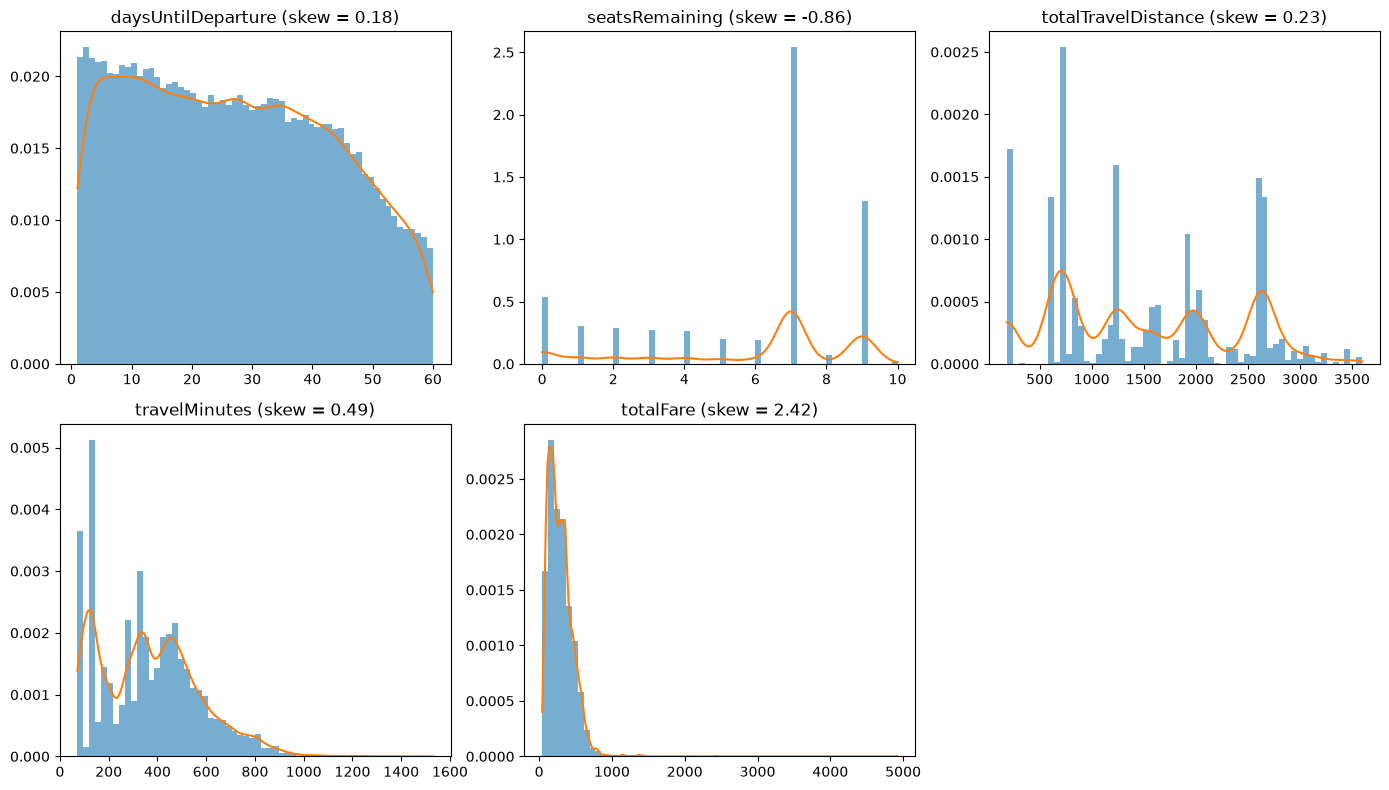

In [18]:
sample = df.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, num_cols):
    values = sample[col].dropna()
    ax.hist(values, bins=60, density=True, alpha=0.6)                  # histogram
    kde_values = values.sample(min(20_000, len(values)), random_state=RANDOM_STATE)
    grid = np.linspace(values.min(), values.max(), 200)
    ax.plot(grid, stats.gaussian_kde(kde_values)(grid))                # smooth KDE curve
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
axes.flat[-1].axis("off")                                              # 5 plots in a 2x3 grid: hide the 6th
plt.tight_layout()
plt.savefig(f"{fig_dir}/hist_features.pdf")
plt.show()

*Interpretation:*
- **Skewed features:** `totalFare` is strongly right-skewed (skew 2.42): most fares are below about 600 USD, with a long tail up to 4,923.60 USD. A log transform of the target is therefore considered in Section 5. `travelMinutes` is mildly right-skewed (skew 0.49) because of a few long connecting trips.
- **Multimodal features:** `totalTravelDistance` has several separate peaks, roughly one per route (e.g., about 185 miles for BOS→LGA and 2,600 miles for LAX→BOS). These hidden groups are the six routes, so distance mostly identifies the route; combined with its missing and invalid values (Section 3), this makes it redundant once the route is included in the model. `travelMinutes` is also multimodal, with peaks for short direct routes (around 100 minutes) and longer routes (around 300–500 minutes), but it also varies within a route depending on whether the trip is nonstop or has connections, so it carries information beyond the route. `daysUntilDeparture` is spread fairly evenly between 1 and about 45 days and becomes less frequent at longer lead times, because flights departing early in the collection period could not be searched that far in advance.
- **Zero-inflated / capped features:** `seatsRemaining` takes only 11 values, with large spikes at 7 and 9 (caps) and at 0 (not reported), so its KDE curve is not meaningful. It will be converted into flags (few seats left, seats unknown) instead of being used as a count.

### 4.3 Categorical features

In [19]:
cat_cols = ["route", "startingAirport", "destinationAirport", "isNonStop", "isBasicEconomy"]
for col in cat_cols:
    counts = df[col].value_counts()
    print(f"{col} ({counts.size} levels):")
    print(pd.DataFrame({"n": counts, "%": (counts / len(df) * 100).round(1)}), "\n")

route (6 levels):
              n     %
route                
ATL→LAX  679981  20.4
LAX→BOS  653973  19.6
DFW→LAX  588254  17.6
ORD→LGA  524764  15.7
BOS→LGA  463776  13.9
CLT→ORD  428758  12.8 

startingAirport (6 levels):
                      n     %
startingAirport              
ATL              679981  20.4
LAX              653973  19.6
DFW              588254  17.6
ORD              524764  15.7
BOS              463776  13.9
CLT              428758  12.8 

destinationAirport (4 levels):
                          n     %
destinationAirport               
LAX                 1268235  38.0
LGA                  988540  29.6
BOS                  653973  19.6
ORD                  428758  12.8 

isNonStop (2 levels):
                 n     %
isNonStop               
False      2068317  61.9
True       1271189  38.1 

isBasicEconomy (2 levels):
                      n     %
isBasicEconomy               
False           2791711  83.6
True             547795  16.4 



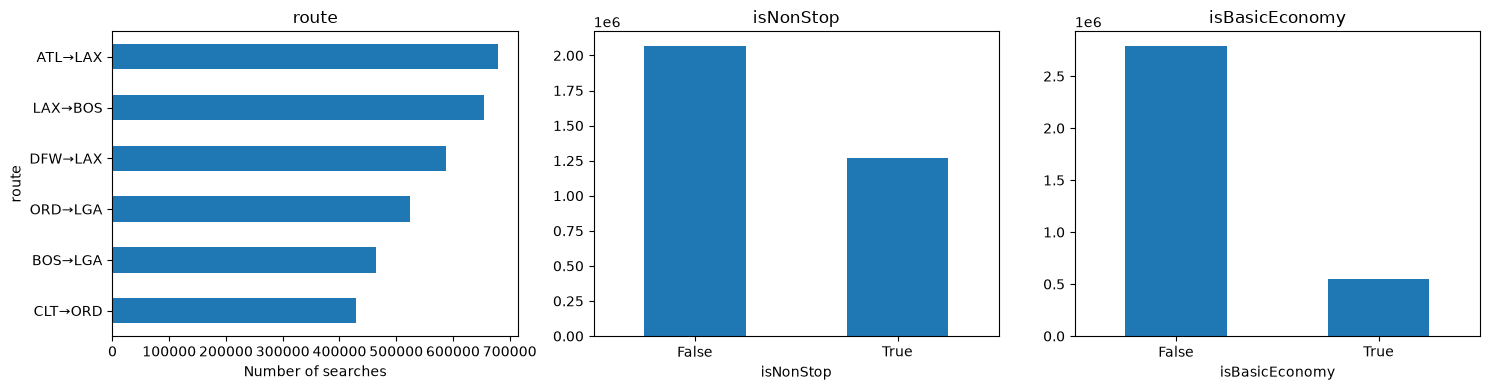

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["route"].value_counts().sort_values().plot.barh(ax=axes[0], title="route")
df["isNonStop"].value_counts().plot.bar(ax=axes[1], title="isNonStop", rot=0)
df["isBasicEconomy"].value_counts().plot.bar(ax=axes[2], title="isBasicEconomy", rot=0)
axes[0].set_xlabel("Number of searches")
plt.tight_layout()
plt.savefig(f"{fig_dir}/categorical_counts.pdf")
plt.show()

*Interpretation:* The six routes are reasonably balanced, from 12.8% (CLT→ORD) to 20.4% (ATL→LAX) of searches, so there are no rare levels to group. Because each origin airport belongs to exactly one selected route, `startingAirport` has exactly the same counts as `route`, and `destinationAirport` is also fully determined by it; both are redundant, so only `route` will be used. `isBasicEconomy` is imbalanced (16.4% True), but with about 548,000 basic economy searches there is enough data to estimate its effect; `isNonStop` is more balanced (38.1% True). All categorical features are nominal, so `route` will be one-hot encoded (one 0/1 column per route, with one route dropped as the reference), while the binary features are used directly as 0/1.

### 4.4 Outlier detection

Outliers are identified with two common rules:
- **IQR rule:** a value is an outlier if it is below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR, where IQR = Q3 − Q1 is the range of the middle 50% of the data. This rule does not depend on the mean, so it works well for skewed features.
- **z-score rule:** a value is an outlier if it is more than 3 standard deviations from the mean (|z| > 3). This rule assumes a roughly symmetric distribution.

The box plots show all numeric features after standardization (z-scores), so they can be compared on the same scale. Finally, the most expensive tickets are inspected to decide whether extreme fares are errors or genuine prices.

In [21]:
rows = []
for col in num_cols:
    x = df[col].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_out = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()   # IQR rule
    z_out = (np.abs((x - x.mean()) / x.std()) > 3).sum()            # z-score rule
    rows.append({"feature": col, "IQR": iqr_out, "IQR %": iqr_out / len(x) * 100,
                 "|z|>3": z_out, "|z|>3 %": z_out / len(x) * 100})
pd.DataFrame(rows).set_index("feature").round(2)

,IQR,IQR %,|z|>3,|z|>3 %
feature,,,,
daysUntilDeparture,0,0.00,0,0.00
seatsRemaining,0,0.00,0,0.00
totalTravelDistance,0,0.00,0,0.00
travelMinutes,10523,0.32,8784,0.26
totalFare,45963,1.38,22736,0.68


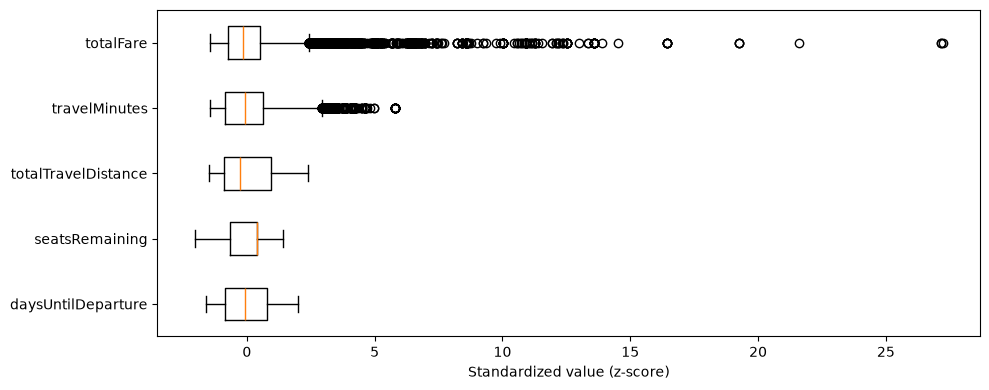

In [23]:
standardized = (sample[num_cols] - df[num_cols].mean()) / df[num_cols].std()
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([standardized[c].dropna() for c in num_cols], orientation="horizontal")
ax.set_yticks(range(1, len(num_cols) + 1), num_cols)
ax.set_xlabel("Standardized value (z-score)")
plt.tight_layout()
plt.savefig(f"{fig_dir}/boxplots.pdf")
plt.show()

In [24]:
df.nlargest(5, "totalFare")[["route", "searchDate", "flightDate", "daysUntilDeparture", "totalFare", "isNonStop", "travelMinutes"]]

,route,searchDate,flightDate,daysUntilDeparture,totalFare,isNonStop,travelMinutes
820866,LAX→BOS,2022-09-12,2022-09-13,1,4923.6,True,330.0
829254,LAX→BOS,2022-09-28,2022-09-29,1,4923.6,True,327.0
1757578,LAX→BOS,2022-09-22,2022-09-23,1,4923.6,True,327.0
2250342,LAX→BOS,2022-09-27,2022-09-28,1,4923.6,True,330.0
2663978,LAX→BOS,2022-09-20,2022-09-21,1,4923.6,True,330.0


*Interpretation:* Only `travelMinutes` and `totalFare` have outliers; `daysUntilDeparture`, `seatsRemaining`, and `totalTravelDistance` have none because their values lie in fixed ranges (the invalid distances found in Section 3.3 are too low rather than extreme, so these rules do not detect them). `travelMinutes` has 0.32% outliers by the IQR rule (0.26% by z-score), which are long connecting trips and are kept. `totalFare` has 1.38% outliers by the IQR rule and 0.68% by z-score; the IQR rule flags more because the distribution is right-skewed. The most extreme fares (z ≈ 27) are all the same 4,923.60 USD nonstop LAX→BOS ticket bought one day before departure, on five different dates. Because the same price repeats consistently, these are not data errors but genuine fares, most likely premium-cabin or full-price last-minute tickets (cabin class was not extracted, so this cannot be confirmed). They are therefore kept, and their influence on the linear regression will be reduced by modeling `log(totalFare)` instead of the raw price.

## 5. Target variable analysis
### 5.1 Regression target: `totalFare`

In [25]:
fare = df["totalFare"]
log_fare = np.log(fare)
print(f"Mean {fare.mean():.2f} | Median {fare.median():.2f} | Std {fare.std():.2f} | Min {fare.min():.2f} | Max {fare.max():.2f}")
print(f"Skew of totalFare:      {fare.skew():.2f}")
print(f"Skew of log(totalFare): {log_fare.skew():.2f}")

# Normality test on the sample (with millions of rows any test rejects normality, so the Q-Q plot matters more)
k2, p = stats.normaltest(np.log(sample["totalFare"]))
print(f"Normality test on log(totalFare), 200k sample: statistic {k2:.1f}, p = {p:.3g}")

Mean 289.88 | Median 262.58 | Std 170.24 | Min 41.59 | Max 4923.60
Skew of totalFare:      2.42
Skew of log(totalFare): -0.25
Normality test on log(totalFare), 200k sample: statistic 4091.5, p = 0


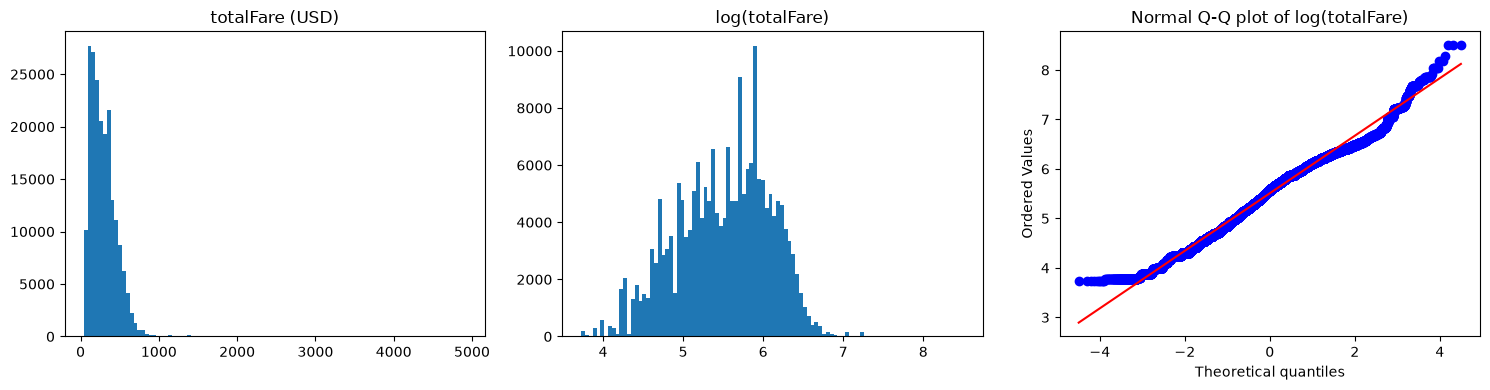

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(sample["totalFare"], bins=100)
axes[0].set_title("totalFare (USD)")
axes[1].hist(np.log(sample["totalFare"]), bins=100)
axes[1].set_title("log(totalFare)")
stats.probplot(np.log(sample["totalFare"]), dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q plot of log(totalFare)")
plt.tight_layout()
plt.savefig(f"{fig_dir}/target.pdf")
plt.show()

In [27]:
df.groupby("route")["totalFare"].describe()[["mean", "50%", "std", "min", "max"]].sort_values("mean")

,mean,50%,std,min,max
route,,,,,
BOS→LGA,142.578850,113.60,85.678213,43.60,1298.6
ORD→LGA,173.939561,160.58,77.756499,55.88,2100.6
DFW→LAX,269.914329,269.58,112.031955,41.59,2499.6
CLT→ORD,281.590109,267.10,123.270675,50.08,2903.1
ATL→LAX,371.101057,359.20,145.194730,50.58,2181.6
LAX→BOS,426.300238,393.60,206.672402,73.58,4923.6


*Interpretation:*
- **Shape:** `totalFare` is unimodal and strongly right-skewed (skew 2.42): the mean (289.88 USD) is above the median (262.58 USD), and a few very expensive tickets reach 4,923.60 USD. The D'Agostino test rejects normality (p ≈ 0), but with 200,000 rows any small deviation is significant, so the Q-Q plot is more informative.
- **Censoring / caps:** there is no upper cap, but there is a floor at the lowest fares (about 41.59 USD), visible as the flat left end of the Q-Q plot.
- **Transformation:** the log transform reduces the skew from 2.42 to −0.25. In the Q-Q plot, log(totalFare) follows the normal line closely except at the extremes (a floor on the left and a heavier tail of expensive fares on the right).
- **Fare by route:** the median fare ranges from 113.60 USD (BOS→LGA) to 393.60 USD (LAX→BOS), so the route strongly affects price, though not only through distance (CLT→ORD is more expensive than the longer DFW→LAX). The standard deviation also grows with the price level (from about 78 USD to 207 USD), which the log transform helps stabilize.

**Decision:** the linear regression will model `log(totalFare)`, and predictions will be converted back to dollars to compute MAE and RMSE, together with R². Instead of a random or stratified split, a time-based split is used (Section 7.2).

### 5.2 Classification target: `wait`

In [28]:
balance = df["wait"].value_counts().sort_index()
print(pd.DataFrame({"n": balance, "%": (balance / len(df) * 100).round(1)}))
print(f"Imbalance ratio (buy now : wait) = {balance[0] / balance[1]:.2f} : 1")
print()
print("Share of 'wait' by route (%):")
print((df.groupby("route")["wait"].mean() * 100).round(1).sort_values())

            n     %
wait               
0     2174183  65.1
1     1165323  34.9
Imbalance ratio (buy now : wait) = 1.87 : 1

Share of 'wait' by route (%):
route
CLT→ORD    27.5
BOS→LGA    30.0
ORD→LGA    34.0
DFW→LAX    35.1
ATL→LAX    37.6
LAX→BOS    41.0
Name: wait, dtype: float64


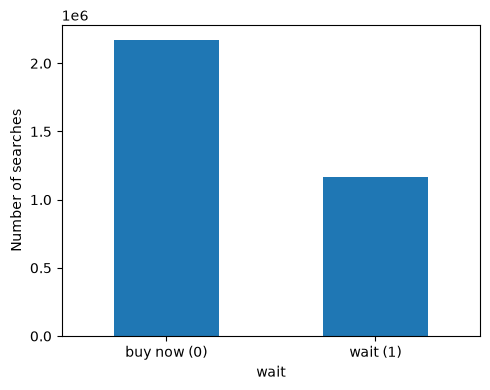

In [29]:
fig, ax = plt.subplots(figsize=(5, 4))
balance.rename({0: "buy now (0)", 1: "wait (1)"}).plot.bar(ax=ax, rot=0)
ax.set_ylabel("Number of searches")
plt.tight_layout()
plt.savefig(f"{fig_dir}/target_wait.pdf")
plt.show()

*Interpretation:* 34.9% of searches are labeled "wait" and 65.1% "buy now", an imbalance ratio of 1.87 : 1. The imbalance is moderate, not severe, so resampling methods such as SMOTE are not needed; class weights may be tested during modeling. Because a baseline that always predicts "buy now" is already correct 65.1% of the time, accuracy alone would be misleading, and the logistic regression will be evaluated with precision, recall, and F1 against this baseline. The share of "wait" labels varies by route, from 27.5% (CLT→ORD) to 41.0% (LAX→BOS): price drops are more frequent on the longer, more expensive routes, so the route is informative for both targets. As discussed in Section 3.1, about 4% of labels may miss an unobserved price drop, so 34.9% is a lower bound.

## 6. Bivariate and multivariate analysis
### 6.1 Numeric features vs. `totalFare`

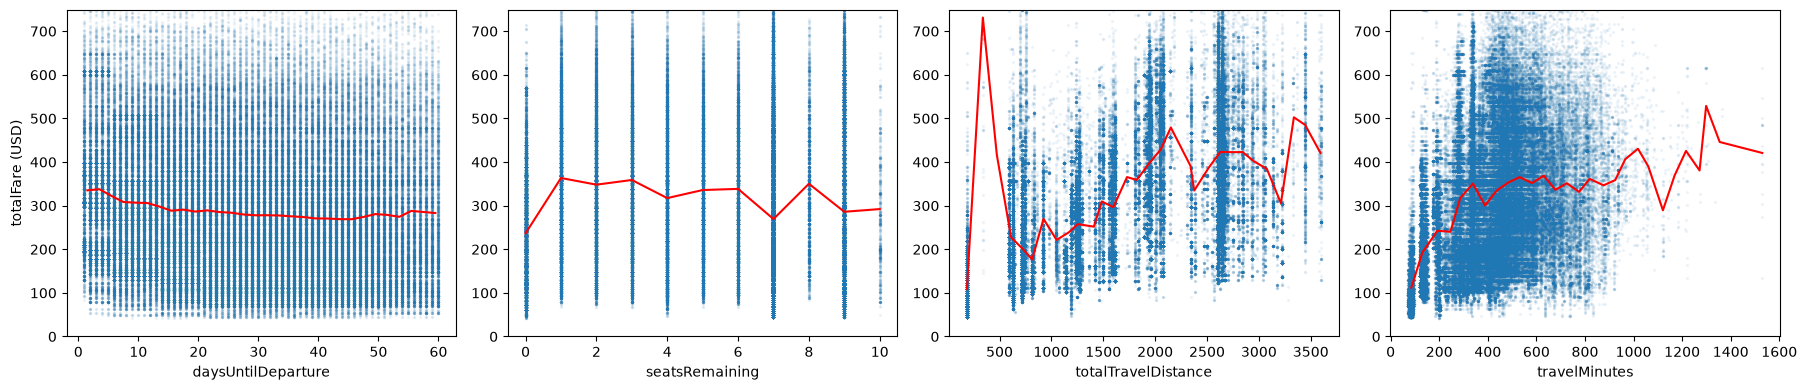

In [30]:
features = ["daysUntilDeparture", "seatsRemaining", "totalTravelDistance", "travelMinutes"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    ax.scatter(sample[col], sample["totalFare"], s=2, alpha=0.05)              # one dot per search
    bins = pd.cut(sample[col], 30)                                             # split the feature into 30 ranges
    binned = sample.groupby(bins, observed=True).agg(x=(col, "mean"), y=("totalFare", "mean"))
    ax.plot(binned["x"], binned["y"], color="red")                             # average fare per range
    ax.set_xlabel(col)
    ax.set_ylim(0, sample["totalFare"].quantile(0.99))                         # hide the extreme top 1% so the trend is visible
axes[0].set_ylabel("totalFare (USD)")
plt.tight_layout()
plt.savefig(f"{fig_dir}/scatter_target.pdf")
plt.show()

In [31]:
assoc = pd.DataFrame({
    "Pearson": [df[c].corr(df["totalFare"]) for c in features],
    "Spearman": [df[c].corr(df["totalFare"], method="spearman") for c in features],
}, index=features)
assoc.reindex(assoc["Spearman"].abs().sort_values(ascending=False).index).round(3)

,Pearson,Spearman
totalTravelDistance,0.581,0.653
travelMinutes,0.384,0.486
daysUntilDeparture,-0.090,-0.114
seatsRemaining,-0.046,-0.071


*Interpretation:* `totalTravelDistance` has the strongest association with fare (Pearson 0.58, Spearman 0.65), but this mostly reflects the route, which sets the price level; combined with its missing values and the invalid low distances (visible as a spike of expensive fares around 300–400 miles), it will be dropped in favor of `route`. `travelMinutes` is moderately associated (0.38 / 0.49), and Spearman is clearly higher than Pearson, indicating a monotone but non-linear effect: fares rise quickly up to about 400 minutes and then level off, which a log-transformed target should capture better. `daysUntilDeparture` has a weak negative association (−0.09 / −0.11): fares fall slowly from about 335 USD one day before departure to about 270 USD around 45 days, then rise slightly. Because this effect is U-shaped, a squared term will be added.

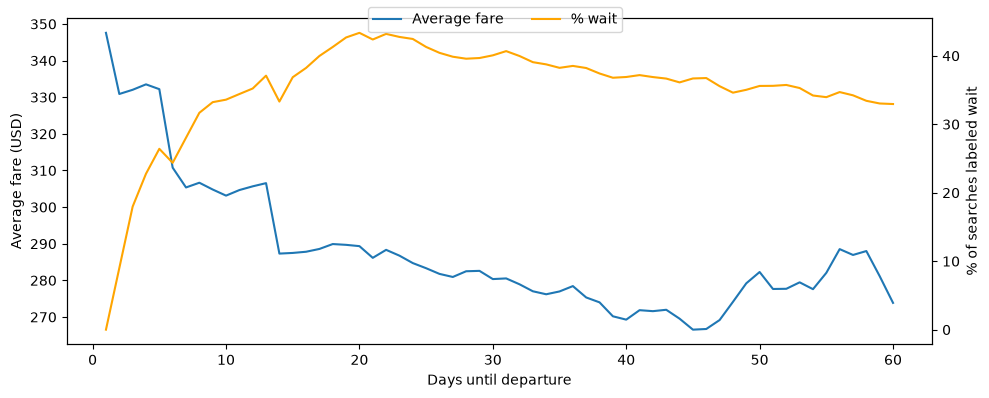

In [32]:
by_day = df.groupby("daysUntilDeparture").agg(avg_fare=("totalFare", "mean"), wait_rate=("wait", "mean"))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(by_day.index, by_day["avg_fare"], label="Average fare")
ax1.set_xlabel("Days until departure")
ax1.set_ylabel("Average fare (USD)")
ax2 = ax1.twinx()                                   # second y-axis on the right, for the % wait
ax2.plot(by_day.index, by_day["wait_rate"] * 100, color="orange", label="% wait")
ax2.set_ylabel("% of searches labeled wait")
fig.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig(f"{fig_dir}/days_vs_targets.pdf")
plt.show()

The plot of both targets by days until departure answers the research question directly. The average fare is highest one day before departure (about 348 USD), drops in two steps between 5 and 6 days and between 13 and 14 days before departure, consistent with airline 7- and 14-day advance-purchase rules, reaches its minimum around 45 days (about 267 USD), and rises again afterward. The share of "wait" labels is close to 0% one day before departure, when there is no time left for the price to drop, rises quickly to a peak of about 43% around 20–23 days, and then slowly declines to about 33% at 60 days; its dips near 6 and 14 days align with the fare steps. Both relationships are clearly non-linear, so `daysUntilDeparture` will enter the models with a squared term or as day ranges that capture the advance-purchase steps.

### 6.2 Categorical features vs. `totalFare`

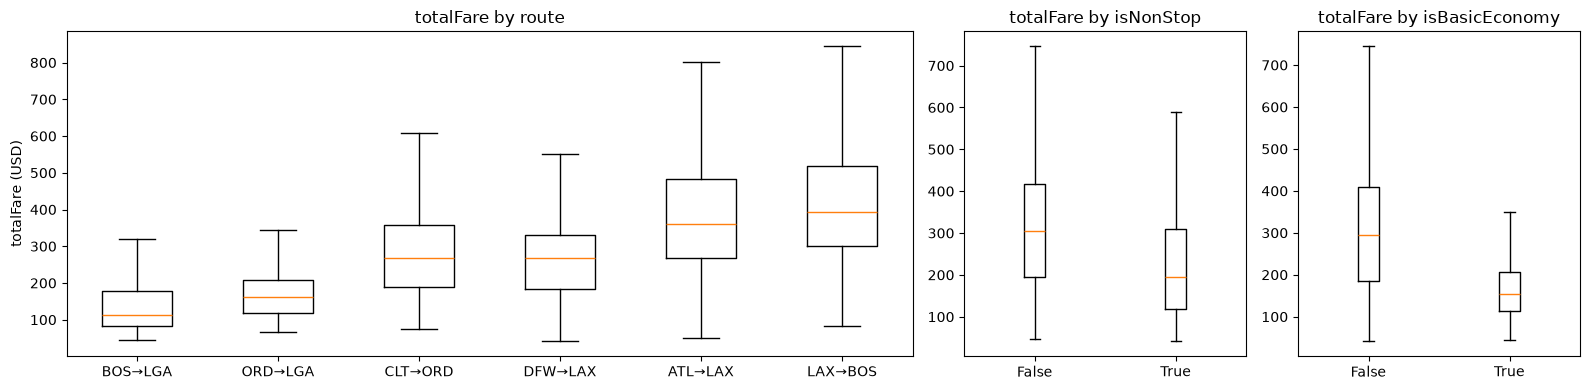

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [3, 1, 1]})
order = df.groupby("route")["totalFare"].median().sort_values().index
axes[0].boxplot([sample.loc[sample["route"] == r, "totalFare"] for r in order], showfliers=False)
axes[0].set_xticks(range(1, len(order) + 1), order)
axes[0].set_title("totalFare by route")
for ax, col in zip(axes[1:], ["isNonStop", "isBasicEconomy"]):
    ax.boxplot([sample.loc[sample[col] == v, "totalFare"] for v in [False, True]], showfliers=False)
    ax.set_xticks([1, 2], ["False", "True"])
    ax.set_title(f"totalFare by {col}")
axes[0].set_ylabel("totalFare (USD)")
plt.tight_layout()
plt.savefig(f"{fig_dir}/cat_target.pdf")
plt.show()

In [34]:
for col in ["isNonStop", "isBasicEconomy"]:
    a = sample.loc[sample[col], "totalFare"]
    b = sample.loc[~sample[col], "totalFare"]
    u, p = stats.mannwhitneyu(a, b)
    print(f"{col}: median True {a.median():.2f} vs False {b.median():.2f} | Mann-Whitney U p = {p:.3g}")

h, p = stats.kruskal(*[g["totalFare"] for _, g in sample.groupby("route")])
print(f"route: Kruskal-Wallis H = {h:,.0f}, p = {p:.3g}")

isNonStop: median True 195.60 vs False 305.61 | Mann-Whitney U p = 0
isBasicEconomy: median True 154.73 vs False 295.60 | Mann-Whitney U p = 0
route: Kruskal-Wallis H = 89,766, p = 0


In [35]:
df.pivot_table(index="route", columns="isNonStop", values="totalFare", aggfunc="median").round(2)

isNonStop,False,True
route,,
ATL→LAX,351.20,398.60
BOS→LGA,186.71,98.60
CLT→ORD,277.70,237.10
DFW→LAX,288.60,235.60
LAX→BOS,389.61,413.61
ORD→LGA,147.60,168.61


*Interpretation:* All three categorical features are associated with fare (Mann–Whitney U and Kruskal–Wallis p ≈ 0). With 200,000 rows any difference is significant, so the size of the differences matters more.

- **Route** has the strongest effect (Kruskal–Wallis H = 89,766): median fares range from about 115 USD (BOS→LGA) to about 395 USD (LAX→BOS), and the spread of fares grows with the price level.
- **Basic economy** tickets cost about half as much as regular fares (median 154.73 vs. 295.60 USD).
- **Nonstop** itineraries appear cheaper overall (median 195.60 vs. 305.61 USD), which is counterintuitive. Comparing within each route shows that this is mostly **confounding by route**: the short, cheap routes are flown mostly nonstop, and within routes the difference is smaller and goes in both directions. Nonstop is more expensive on ATL→LAX, LAX→BOS, and ORD→LGA, but cheaper on BOS→LGA, CLT→ORD, and DFW→LAX (on BOS→LGA, a connecting trip for a 185-mile route goes through a distant hub). The effect of `isNonStop` therefore depends on the route,

### 6.3 Correlation and multicollinearity

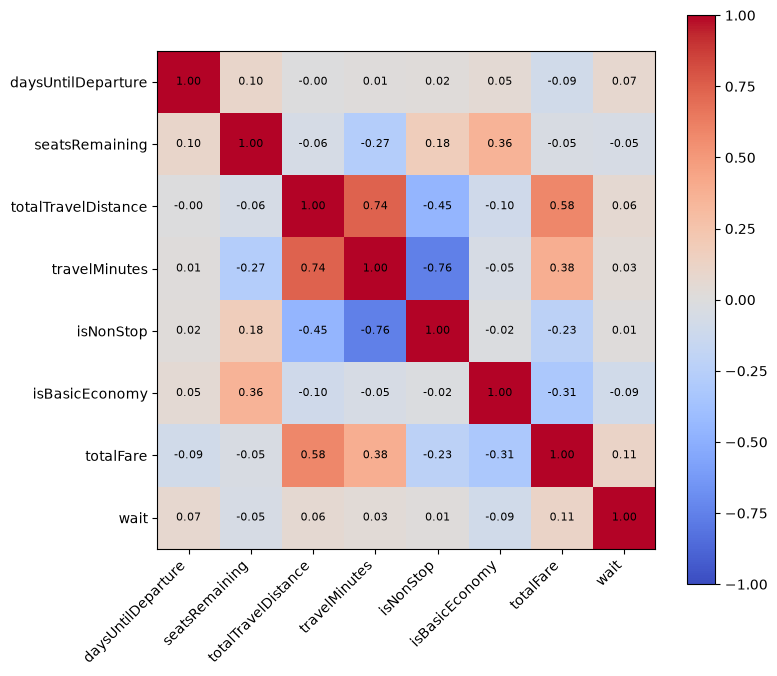

In [36]:
corr_cols = features + ["isNonStop", "isBasicEconomy", "totalFare", "wait"]
corr = df[corr_cols].astype(float).corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)              # colors: blue = negative, red = positive
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)   # write each value
fig.colorbar(im)
plt.tight_layout()
plt.savefig(f"{fig_dir}/corr_heatmap.pdf")
plt.show()

In [37]:
feat_cols = features + ["isNonStop", "isBasicEconomy"]
fc = df[feat_cols].astype(float).corr()
pairs = [(a, b, round(fc.loc[a, b], 2)) for i, a in enumerate(feat_cols) for b in feat_cols[i + 1:] if abs(fc.loc[a, b]) >= 0.70]
print("Pairs with |r| >= 0.70:", pairs if pairs else "none")

# VIF = diagonal of the inverse correlation matrix of the features
X = df[feat_cols].dropna().astype(float)
vif = pd.Series(np.diag(np.linalg.inv(X.corr().values)), index=feat_cols, name="VIF")
vif.round(2)

Pairs with |r| >= 0.70: [('totalTravelDistance', 'travelMinutes', np.float64(0.74)), ('travelMinutes', 'isNonStop', np.float64(-0.76))]


daysUntilDeparture     1.02
seatsRemaining         1.19
totalTravelDistance    2.41
travelMinutes          4.68
isNonStop              2.68
isBasicEconomy         1.18
Name: VIF, dtype: float64

*Interpretation:* Two pairs of features are highly correlated: `totalTravelDistance` and `travelMinutes` (r = 0.74), because longer trips take longer, and `travelMinutes` and `isNonStop` (r = −0.76), because connections add travel time. However, all Variance Inflation Factors are below 5, so there is no severe multicollinearity; the highest is `travelMinutes` (VIF 4.68), which overlaps with both distance and nonstop. Dropping `totalTravelDistance`, as already planned because of its missing and invalid values and because the route sets the distance, removes the strongest overlap, and the regularization planned for the models will handle the remaining correlation between `travelMinutes` and `isNonStop`. For the classification target, all correlations with `wait` are weak (|r| ≤ 0.11): the largest are `totalFare` (0.11, more expensive tickets drop in price more often) and `isBasicEconomy` (−0.09). No single feature predicts `wait` linearly, so the logistic regression will rely on combining features and on non-linear terms for `daysUntilDeparture`, and its performance is expected to be modest.

### 6.4 Associations between categorical features

In [38]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)                                   # counts for each combination of categories
    chi2, p, _, _ = stats.chi2_contingency(table)               # chi-square test of independence
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))   # scale chi-square to 0-1
    return chi2, p, v

for a, b in [("route", "isNonStop"), ("route", "isBasicEconomy"), ("isNonStop", "isBasicEconomy"),
             ("route", "wait"), ("isNonStop", "wait"), ("isBasicEconomy", "wait")]:
    chi2, p, v = cramers_v(df[a], df[b])
    print(f"{a} vs {b}: chi2 = {chi2:,.0f}, p = {p:.3g}, Cramér's V = {v:.3f}")

route vs isNonStop: chi2 = 584,474, p = 0, Cramér's V = 0.418
route vs isBasicEconomy: chi2 = 131,904, p = 0, Cramér's V = 0.199
isNonStop vs isBasicEconomy: chi2 = 1,626, p = 0, Cramér's V = 0.022
route vs wait: chi2 = 28,500, p = 0, Cramér's V = 0.092
isNonStop vs wait: chi2 = 237, p = 1.75e-53, Cramér's V = 0.008
isBasicEconomy vs wait: chi2 = 26,273, p = 0, Cramér's V = 0.089


*Interpretation:* All χ² tests reject independence (p ≈ 0), but with 3.3 million rows this is expected, so Cramér's V is used to judge strength. The strongest association is between `route` and `isNonStop` (V = 0.418): whether an itinerary is nonstop depends strongly on the route, which confirms the confounding found in Section 6.2 and supports a possible route × nonstop interaction. `route` and `isBasicEconomy` are moderately associated (V = 0.199), meaning basic economy fares are offered more on some routes, while `isNonStop` and `isBasicEconomy` are essentially independent (V = 0.022). The associations with `wait` are all weak: `route` (V = 0.092) and `isBasicEconomy` (V = 0.089) are the most informative, and `isNonStop` is essentially unrelated to price drops (V = 0.008). As in Section 6.3, no single feature strongly predicts `wait`, so the classifier will need to combine features.

### 6.5 Pair plot of key features

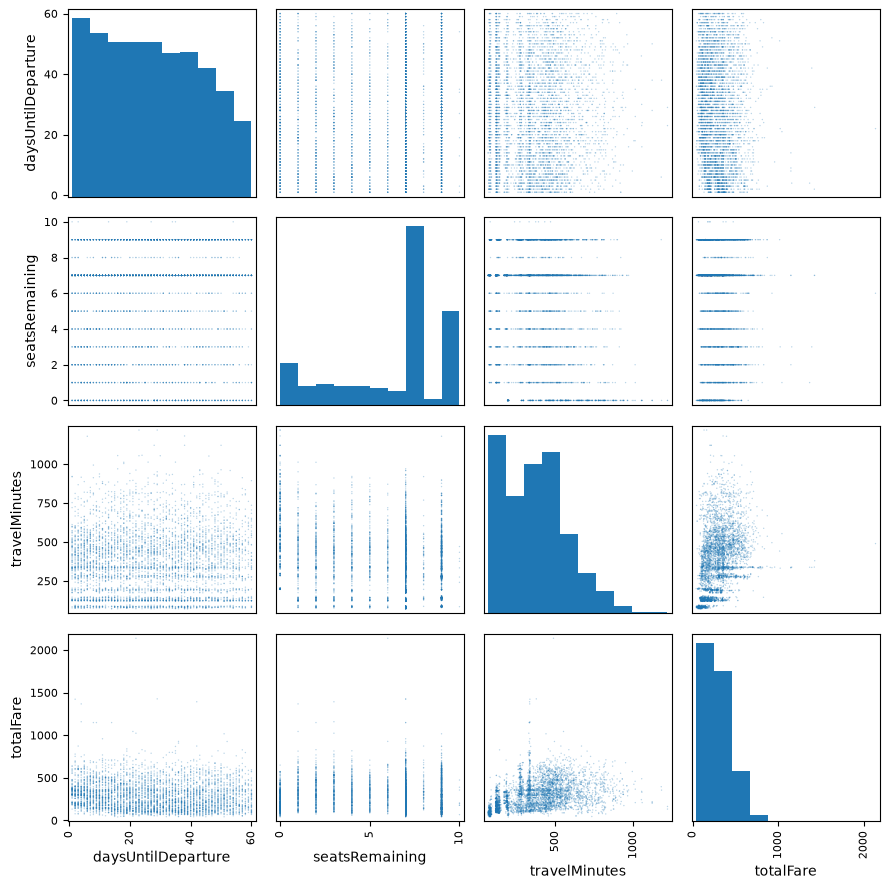

In [39]:
small = sample.sample(5_000, random_state=RANDOM_STATE)
pd.plotting.scatter_matrix(small[["daysUntilDeparture", "seatsRemaining", "travelMinutes", "totalFare"]],
                           figsize=(9, 9), s=4, alpha=0.3, diagonal="hist")
plt.tight_layout()
plt.savefig(f"{fig_dir}/pairplot.pdf")
plt.show()

*Interpretation:* The pair plot confirms the earlier findings. The only clear relationship is between `travelMinutes` and `totalFare`, which is positive and split into clusters that correspond to the routes; the horizontal bands in `travelMinutes` (around 80, 130, and 330 minutes) are the fixed durations of nonstop flights on specific routes. `seatsRemaining` appears only as stripes at whole numbers, with heavy stripes at the caps (7 and 9) and at 0 (not reported). `daysUntilDeparture` shows no visible pattern with the other variables at the level of individual searches; its effect only appears when fares are averaged by day (Section 6.1). These patterns suggest three feature-engineering steps: one-hot encoding of `route` (which separates the clusters), flags for `seatsRemaining`, and non-linear terms for `daysUntilDeparture`.

## 7. Special checks
### 7.1 Time trends

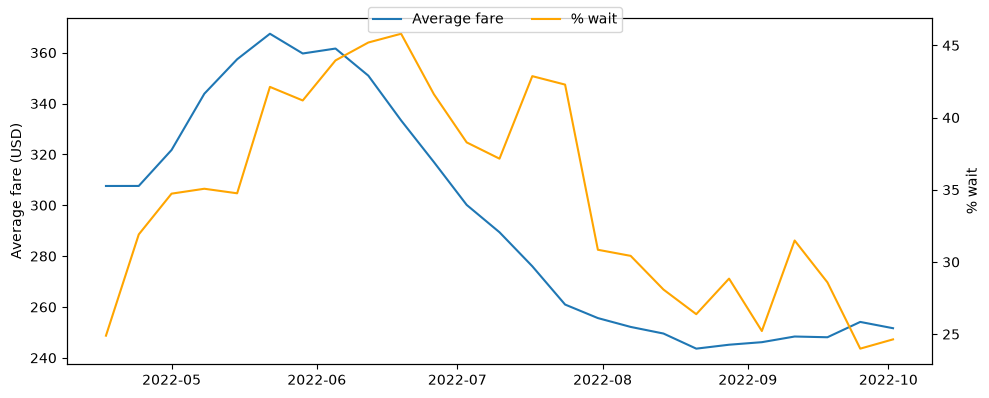

In [40]:
weekly = df.set_index("searchDate").resample("W").agg({"totalFare": "mean", "wait": "mean"})

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(weekly.index, weekly["totalFare"], label="Average fare")
ax1.set_ylabel("Average fare (USD)")
ax2 = ax1.twinx()
ax2.plot(weekly.index, weekly["wait"] * 100, color="orange", label="% wait")
ax2.set_ylabel("% wait")
fig.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig(f"{fig_dir}/time_trend.pdf")
plt.show()

### 7.2 Train/test comparison (time-based split)

In [42]:
cutoff = df["searchDate"].quantile(0.80).normalize()
train = df[df["searchDate"] < cutoff]
test = df[df["searchDate"] >= cutoff + pd.Timedelta(days=7)]

print(f"Train: searches before {cutoff.date()} ({len(train):,} rows)")
print(f"Test:  searches from {(cutoff + pd.Timedelta(days=7)).date()} ({len(test):,} rows)")
print(f"Gap:   {len(df) - len(train) - len(test):,} rows dropped")
pd.DataFrame({
    "train": [train["totalFare"].mean(), train["totalFare"].median(), train["wait"].mean() * 100, train["daysUntilDeparture"].mean()],
    "test":  [test["totalFare"].mean(),  test["totalFare"].median(),  test["wait"].mean() * 100,  test["daysUntilDeparture"].mean()],
}, index=["mean fare", "median fare", "% wait", "mean days until departure"]).round(2)

Train: searches before 2022-08-25 (2,653,298 rows)
Test:  searches from 2022-09-01 (572,454 rows)
Gap:   113,754 rows dropped


,train,test
mean fare,300.39,249.62
median fare,271.58,217.66
% wait,36.80,27.49
mean days until departure,28.07,23.71
